In [1]:
%pylab inline
import os
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import sim_analysis_utilities as utilities
import smatch

Populating the interactive namespace from numpy and matplotlib


In [9]:
cat2=pyfits.getdata('wrkDir/database/s19-Hironao-2/fields/GAMA09H.fits')[0::5]

# GAMA09H 

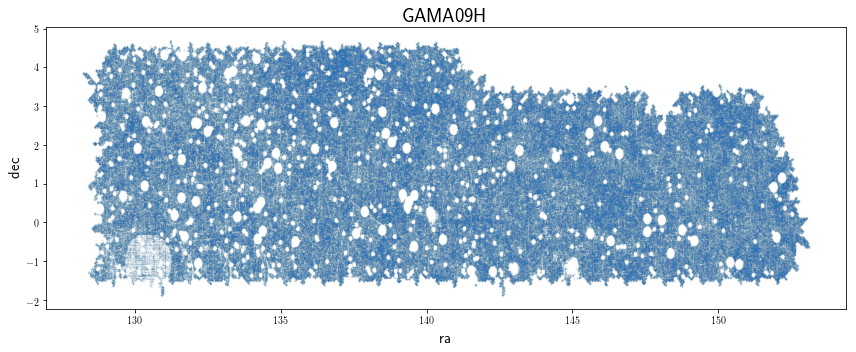

In [10]:
ra=cat2['i_ra']
dec=cat2['i_dec']
fn='GAMA09H'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(ra,dec,s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

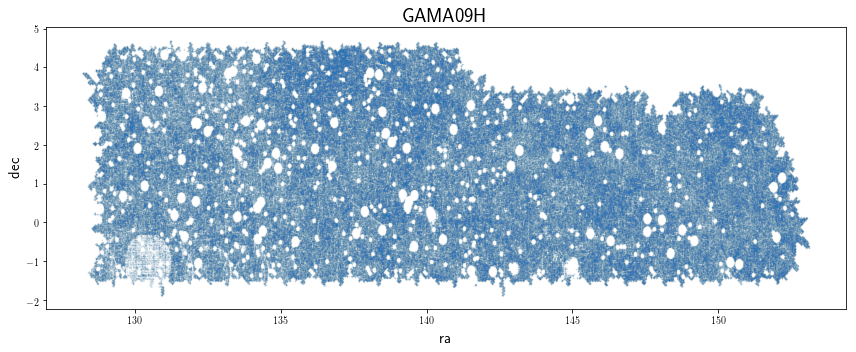

In [11]:
wlmask=utilities.update_wl_flags(cat2)['weak_lensing_flag']
ra=cat2[wlmask]['i_ra']
dec=cat2[wlmask]['i_dec']
fn='GAMA09H'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(ra,dec,s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

In [39]:
def get_mask_visit_104994(ra,dec):
    def _calDistanceAngle(a1, d1):
        a2=130.43
        d2=-1.02
        a1_f64 = np.array(a1, dtype = np.float64)*np.pi/180.
        d1_f64 = np.array(d1, dtype = np.float64)*np.pi/180.
        a2_f64 = np.array(a2, dtype = np.float64)*np.pi/180.
        d2_f64 = np.array(d2, dtype = np.float64)*np.pi/180.
        return np.arccos(np.cos(d1_f64)*np.cos(d2_f64)*np.cos(a1_f64-a2_f64)+np.sin(d1_f64)*np.sin(d2_f64))/np.pi*180.
    d=_calDistanceAngle(ra,dec)
    mask=(ra>130.5)&(ra<131.5)&(dec<-1.5)
    return (d>0.77)&(~mask)

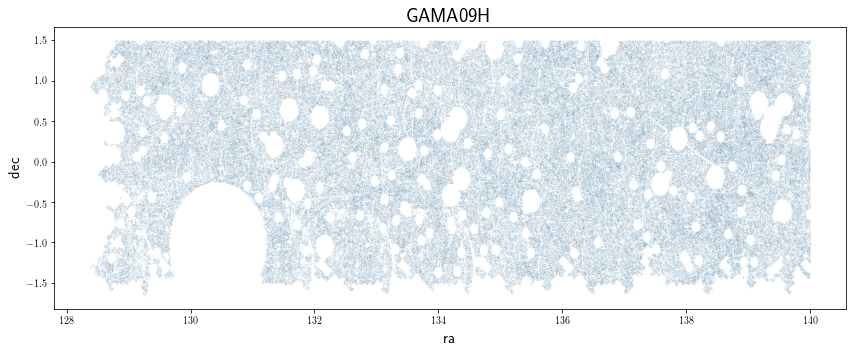

In [40]:
mask1=(ra<140)&(dec<1.5)
ra2=ra[mask1]
dec2=dec[mask1]
mask=get_mask_visit_104994(ra2,dec2)
ra2=ra2[mask]
dec2=dec2[mask]
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(ra2,dec2,s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

In [41]:
tract=cat2['tract'][wlmask]
tract=tract[mask1][~mask]

## Overlap tracts
9071,9072,9314,9315

## Reason
This should have indeed been removed from the visit list.  Comment to that visit:

>     Something wrong for tracking. Need retake => visit=104994 yasuda@stars

I think this suggests that we need an automated and robust mechanism to identify
bad visits.  A lesson for PFS.

Just in case you did not know, there is a public version of the HSC obslog:

https://hscobslog.naoj.org/obslog/session/new

-Masayuki 

## Solution

In [43]:
def get_mask_visit_104994(data):
    ra=data['i_ra']
    dec=data['i_dec']
    def _calDistanceAngle(a1, d1):
        a2=130.43
        d2=-1.02
        a1_f64 = np.array(a1, dtype = np.float64)*np.pi/180.
        d1_f64 = np.array(d1, dtype = np.float64)*np.pi/180.
        a2_f64 = np.array(a2, dtype = np.float64)*np.pi/180.
        d2_f64 = np.array(d2, dtype = np.float64)*np.pi/180.
        return np.arccos(np.cos(d1_f64)*np.cos(d2_f64)*np.cos(a1_f64-a2_f64)+np.sin(d1_f64)*np.sin(d2_f64))/np.pi*180.
    d=_calDistanceAngle(ra,dec)
    mask=(ra>130.5)&(ra<131.5)&(dec<-1.5)
    return (d>0.77)&(~mask)

Dir='./wrkDir/s19/s19-1/.catalog_obs_reGaus_calibrated/fields/'
fieldname='GAMA09H'

inFname =   os.path.join(Dir,'%s_calibrated.fits' %(fieldname))
data    =   pyfits.getdata(inFname)
mask=get_mask_visit_104994(data)
data    =   data[mask]

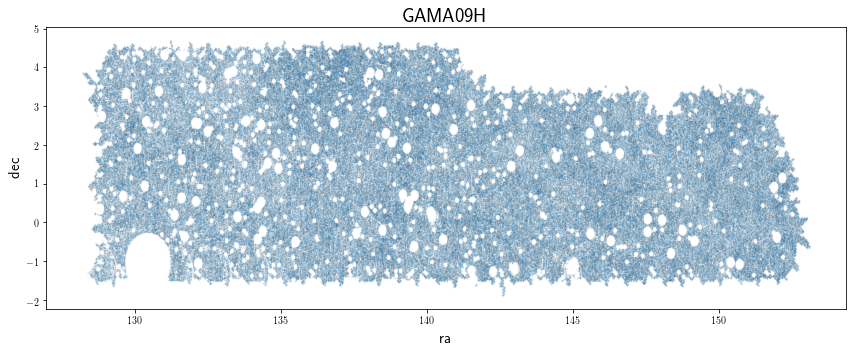

In [44]:
ra=data['i_ra'][0::8]
dec=data['i_dec'][0::8]
fn='GAMA09H'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(ra,dec,s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

In [45]:
pyfits.writeto(inFname,data,overwrite=True)

# XMM

In [ ]:
cat2=pyfits.getdata('wrkDir/database/s19-Hironao-2/fields/XMM.fits')[0::8]

In [ ]:
ra=cat2['i_ra']
dec=cat2['i_dec']
fn='XMM'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(ra,dec,s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

In [3]:
data=astTable.Table.read('wrkDir/s19/s19-1/problem/under-density-region.fits')

In [ ]:
mask=(data['tract']==8280)
mask&=(data['patch']==207)
wlmask=utilities.update_wl_flags(data)['weak_lensing_flag']

In [ ]:
dataX=data[mask]
raX=dataX['i_ra']
decX=dataX['i_dec']
fn='8280-27'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(raX,decX,s=0.8,alpha=.8)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

In [ ]:
dataX=data[mask&wlmask]
raX=dataX['i_ra']
decX=dataX['i_dec']
fn='tract 8280, wl mask'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(raX,decX,s=0.8,alpha=.8)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

In [ ]:
maskN=(~dataX['i_pixelflags_clipped'])
dataX=dataX[maskN]
raX=dataX['i_ra']
decX=dataX['i_dec']
fn='8280-27, wl mask,CLIPPED'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(raX,decX,s=0.8,alpha=.8)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

In [ ]:
maskN=(~data['i_pixelflags_inexact_psf'])
dataX=data[maskN&mask&wlmask]
raX=dataX['i_ra']
decX=dataX['i_dec']
fn='8280-27, wl mask,INEXACTPSF'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(raX,decX,s=0.8,alpha=.8)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

```sql
NOT meas.i_deblend_skipped                  AND
 -- NOT meas.i_cmodel_flag_badcentroid      AND # This flag was not included in S16A, but if we find anything wrong, we can get it back.
 NOT meas2.i_sdsscentroid_flag          AND
 NOT meas.i_pixelflags_edge                 AND
 NOT meas.i_pixelflags_interpolatedcenter  AND
 NOT meas.i_pixelflags_saturatedcenter     AND
 NOT meas.i_pixelflags_crcenter            AND
 NOT meas.i_pixelflags_bad                  AND
 NOT meas.i_pixelflags_suspectcenter       AND
 NOT meas.i_pixelflags_clipped          AND
 meas.i_detect_isprimary                     AND
 NOT meas2.i_hsmshaperegauss_flag            AND 
```